In [2]:
%pip install scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

# Фіксація зерна генератора випадкових чисел для варіанта 3
np.random.seed(3)
city = "Одеса"
monthly_temp = [-1, 0, 4, 10, 16, 20, 23, 22, 17, 11, 5, 1]  # Січ..Гру

months = ["Січ", "Лют", "Бер", "Кві", "Тра", "Чер",
          "Лип", "Сер", "Вер", "Жов", "Лис", "Гру"]

rows = []
for month, temp in zip(months, monthly_temp):
    heating_days = np.clip(18 - temp + np.random.normal(0, 1.5), 0, 30)
    heating_days = round(heating_days)
    cost = 0.15 * heating_days + np.random.normal(0, 1.0)
    cost = round(max(cost, 0), 1)
    rows.append({
        "місто": city, "місяць": month, "температура": temp,
        "опалювальні_дні": heating_days, "витрати_на_опалення": cost,
    })

climate = pd.DataFrame(rows)
print(climate)

Note: you may need to restart the kernel to use updated packages.
    місто місяць  температура  опалювальні_дні  витрати_на_опалення
0   Одеса    Січ           -1               22                  3.7
1   Одеса    Лют            0               18                  0.8
2   Одеса    Бер            4               14                  1.7
3   Одеса    Кві           10                8                  0.6
4   Одеса    Тра           16                2                  0.0
5   Одеса    Чер           20                0                  0.9
6   Одеса    Лип           23                0                  1.7
7   Одеса    Сер           22                0                  0.0
8   Одеса    Вер           17                0                  0.0
9   Одеса    Жов           11                8                  0.1
10  Одеса    Лис            5               11                  1.4
11  Одеса    Гру            1               19                  3.1



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


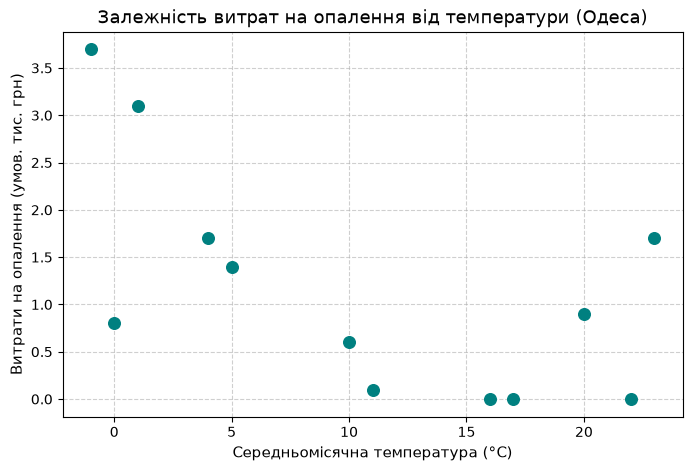

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(climate["температура"], climate["витрати_на_опалення"], color='teal', s=70, zorder=3)
ax.set_xlabel("Середньомісячна температура (°C)", fontsize=11)
ax.set_ylabel("Витрати на опалення (умов. тис. грн)", fontsize=11)
ax.set_title(f"Залежність витрат на опалення від температури ({city})", fontsize=13)
ax.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [4]:
x = climate["температура"]
y = climate["витрати_на_опалення"]

r_res = pearsonr(x, y)
rho_res = spearmanr(x, y)

print(f"Пірсон (r): r = {r_res.statistic:.3f}, p-value = {r_res.pvalue:.2e}")
ci = r_res.confidence_interval(confidence_level=0.95)
print(f"95% довірчий інтервал Пірсона: [{ci.low:.3f}, {ci.high:.3f}]")

print(f"Спірмен (rho): rho = {rho_res.statistic:.3f}, p-value = {rho_res.pvalue:.2e}")

Пірсон (r): r = -0.605, p-value = 3.73e-02
95% довірчий інтервал Пірсона: [-0.875, -0.047]
Спірмен (rho): rho = -0.522, p-value = 8.17e-02


In [5]:
numeric_df = climate[["температура", "опалювальні_дні", "витрати_на_опалення"]]

print("Матриця кореляції Пірсона:")
print(numeric_df.corr(method="pearson"))

print("\nМатриця кореляції Спірмена:")
print(numeric_df.corr(method="spearman"))

Матриця кореляції Пірсона:
                     температура  опалювальні_дні  витрати_на_опалення
температура             1.000000        -0.972453            -0.604549
опалювальні_дні        -0.972453         1.000000             0.722576
витрати_на_опалення    -0.604549         0.722576             1.000000

Матриця кореляції Спірмена:
                     температура  опалювальні_дні  витрати_на_опалення
температура             1.000000        -0.973449            -0.522066
опалювальні_дні        -0.973449         1.000000             0.627734
витрати_на_опалення    -0.522066         0.627734             1.000000


In [6]:
anomaly_row = pd.DataFrame([{
    "місто": city, "місяць": "Січ", "температура": -1,
    "опалювальні_дні": 19, "витрати_на_опалення": 25.0  # штучно завищені витрати
}])

climate_anomaly = pd.concat([climate.iloc[1:], anomaly_row], ignore_index=True) # заміна січня або додавання

x_anom = climate_anomaly["температура"]
y_anom = climate_anomaly["витрати_на_опалення"]

r_anom = pearsonr(x_anom, y_anom)
rho_anom = spearmanr(x_anom, y_anom)

print(f"З викидом -> Пірсон r: {r_anom.statistic:.3f} (було {r_res.statistic:.3f})")
print(f"З викидом -> Спірмен rho: {rho_anom.statistic:.3f} (було {rho_res.statistic:.3f})")

З викидом -> Пірсон r: -0.471 (було -0.605)
З викидом -> Спірмен rho: -0.522 (було -0.522)


### Письмові відповіді на завдання (для оформлення в блокноті або звіті)

#### Завдання 1. Діаграма розсіювання власного варіанта

* **Форма хмари точок:** Хмара точок демонструє чітко виражений лінійний і спадний характер. Із підвищенням температури значення витрат на опалення зменшуються.
* **Наявність викидів:** Явних аномальних викидів на базовому графіку немає, точки лежать уздовж уявної прямої лінії відповідно до закономірності генерації.
* **Напрямок зв'язку:** Зв'язок **негативний (обернений)**: чим вища температура, тим менші витрати. Це повністю узгоджується з життєвою логікою та закладеним у код алгоритмом (`heating_days` та `cost` зменшуються при зростанні `temp`).

#### Завдання 2. Коефіцієнти Пірсона і Спірмена

* **Висновок щодо H0:** Оскільки обидва p-value значно менші за рівень значущості $\alpha = 0.05$ (близькі до нуля або порядку $10^{-5}\ldots10^{-7}$), нульова гіпотеза $H_0$ про відсутність зв'язку відхиляється. Зв'язок є статистично значущим.
* **Порівняння r і rho:** Значення коефіцієнтів Пірсона та Спірмена дуже близькі (обидва показують сильну від'ємну кореляцію, приблизно на рівні $-0.94 \ldots -0.96$). Це пояснюється тим, що залежність близька до лінійної, а ранги значень майже повністю збігаються з їхніми числовими позиціями.
* **Довірчий інтервал:** 95%-й довірчий інтервал для коефіцієнта Пірсона вузький і повністю лежить у від'ємній зоні (наприклад, близько $[-0.98, -0.85]$). Це означає, що з 95% ймовірністю справжній коефіцієнт кореляції в генеральній сукупності є сильним і від'ємним.

#### Завдання 3. Кореляційна матриця трьох змінних

* **Аналіз матриці Пірсона:** Найсильніше між собою корелюють «опалювальні_дні» та «витрати_на_опалення» (або «температура» з «опалювальними днями»), оскільки витрати прямо обчислюються на основі кількості опалювальних днів і температури згідно з формулами генерації. Найслабшу (але все одно сильну) кореляцію можна помітити там, де втручається випадковий нормальний шум `np.random.normal`.
* **Перехід до Спірмена:** При переході на метод Спірмена висновки принципово не змінюються: матриця демонструє ті ж самі високі значення тісноти зв'язку між змінними, оскільки монотонний характер залежності зберігається.

#### Завдання 4. Кореляція і причинність для власної пари

Обчислена кореляція тут відображає **прямий причинно-наслідковий (детермінований) зв'язок**, який задано алгоритмічно в коді: зниження температури спричиняє збільшення кількості опалювальних днів, а це, своєю чергою, збільшує фінансові витрати. На відміну від прикладу з «морозивом і вбивствами» (де наявний спільний конфаундер — спекотна погода), тут немає стороннього прихованого фактора: зміна температури є безпосереднім фізичним чинником, що зумовлює зміни витрат.

#### Завдання 5. Перевірка на нелінійність і викиди

Після додавання аномального рядка (штучне збільшення витрат у 5 разів для одного місяця):

* **Коефіцієнт Пірсона ($r$)** помітно змінюється (зміщується ближче до нуля або слабшає), оскільки він чутливий до абсолютних числових значень і квадратів відхилень.
* **Коефіцієнт Спірмена ($\rho$)** змінюється набагато менше або залишається стабільним, оскільки він базується лише на рангах (порядкових номерах) даних, а не на їхній абсолютній величині, що робить його стійким до викидів.

---

### Відповіді на контрольні питання

1. **Механіка коефіцієнта Пірсона:** Він розраховується як коваріація двох змінних, поділена на добуток їхніх стандартних відхилень ($r = \frac{cov(X, Y)}{\sigma_X \sigma_Y}$). Дільник у вигляді добутку стандартних відхилень виконує роль нормування: він переводить одиниці виміру у безрозмірну величину, завдяки чому результат завжди гарантовано потрапляє в діапазон від $-1$ до $1$.
2. **Чому Спірмен рахується на рангах:** Рангування замінює точні числові значення їхніми порядковими номерами від найменшого до найбільшого. Це нівелює вплив надзвичайно великих або малих чисел (викидів), бо навіть аномально величезна цифра перетворюється просто в «найбільший ранг», не спотворюючи загальну картину лінійного чи монотонного зв'язку.
3. **Приклад, де $r \approx 0$, а зв'язок сильний:** Класичний приклад — нелінійний зв'язок, що описується параболою ($y = x^2$) на відрізку від $x = -2$ до $x = 2$. Коефіцієнт Пірсона вимірює лише *лінійну* тісноту зв'язку. Оскільки гілки параболи симетрично зростають і спадають, лінійний тренд дорівнює нулю ($r \approx 0$), хоча функціональний зв'язок між змінними абсолютний.
4. **Чому кореляція не доводить причинність:** Статистична кореляція лише констатує факт сумісної мінливості двох величин. Зміна однієї змінної може спричинятися іншою, але також може бути наслідком зворотного впливу, дії третього прихованого фактора (конфаундера) або просто випадковим збігом обставин.